# 02. Modelagem Preditiva de Risco de Queimadas — Baselines, LightGBM e Validação Espaçotemporal

## 1. Visão Geral e Estrutura de Modelagem
Neste notebook, desenvolvemos e comparamos a performance dos modelos de aprendizado de máquina para prever a probabilidade de ocorrência de queimadas nos próximos 7 dias em cada célula de grade de Mato Grosso (~0,5° ≈ 56 km).

### Modelos Avaliados:
1. **Baseline 1 — Persistência Empírica**: Risco condicional $P(\text{target}=1 \mid \text{fire\_count\_7d} \in \text{faixa})$ derivado estritamente do conjunto de treino (sem números mágicos ad-hoc).
2. **Baseline 2 — Climatologia**: Frequência histórica empírica de queimadas observada para aquela célula e mês específico durante os anos de treino.
3. **Regressão Logística**: Modelo linear balanceado servindo como benchmark estatístico clássico com padronização de features (`StandardScaler`).
4. **LightGBM (Raw)**: Gradient Boosted Trees otimizado com busca bayesiana de hiperparâmetros (**Optuna**) utilizando **Validação Cruzada em Blocos Espaciais Contíguos** (Norte, Centro e Sul de MT) e ponderação de classe (`scale_pos_weight`).
5. **LightGBM (Platt Calibrated)**: Calibração sigmoide (Platt Scaling) ajustada sobre conjunto de validação temporal (ano 2023), preservando a ordenação de ranking (PR-AUC) enquanto minimiza o Brier score e calibra a probabilidade predita à taxa base real.

### Estratégia de Validação sem Vazamento:
- **Divisão Temporal Out-of-Time**: Treinamento em dados de **2016 a 2023** (1,48 milhão de amostras); Teste cego estrito em **2024 a 2025** (370 mil amostras, incluindo o ano extremo de 2024).
- **Validação Espacial Contígua**: Otimização de hiperparâmetros com 3 blocos geográficos contíguos (Norte amazônico, Centro cerrado e Sul pantaneiro), impedindo contágio de células vizinhas.
- **Validação Walk-Forward**: Avaliação expansiva multi-ano de 2021 a 2025.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)

PROJECT_ROOT = Path("..")


## 2. Carregamento dos Resultados da Execução Real
Carregamos as métricas calculadas na execução do pipeline em `reports/model_comparison.csv` e os metadados em `models/training_metadata.json`.


In [2]:
results_path = PROJECT_ROOT / "reports" / "model_comparison.csv"
meta_path = PROJECT_ROOT / "models" / "training_metadata.json"

results_df = pd.read_csv(results_path)
with open(meta_path, "r", encoding="utf-8") as f:
    meta = json.load(f)

print("=" * 70)
print(f"Período de Treino: {meta['train_period']} ({meta['train_size']:,} amostras)")
print(f"Período de Teste:  {meta['test_period']} ({meta['test_size']:,} amostras)")
print(f"Estratégia de Validação Espacial: {meta.get('spatial_block_cv', 'N/A')}")
print(f"p-value vs Climatologia (Paired Bootstrap): {meta.get('p_value_vs_climatology', 'N/A')}")
print("=" * 70)
results_df


Período de Treino: 2016-01-01 to 2023-12-31 (1,478,532 amostras)
Período de Teste:  2024-01-01 to 2025-12-24 (366,344 amostras)
Estratégia de Validação Espacial: Contiguous (North / Central / South MT)
p-value vs Climatologia (Paired Bootstrap): 0.0


,model,PR-AUC,ROC-AUC,Brier,Recall@P50
0,Persistence (Empirical),0.4293,0.7260,0.1074,0.5281
1,Climatology,0.5169,0.8521,0.1079,0.4855
2,LogisticRegression,0.5464,0.8277,0.1666,0.5941
3,LightGBM (Raw),0.6205,0.8793,0.1474,0.6643
4,LightGBM (Platt Calibrated),0.6205,0.8793,0.0941,0.6643


## 3. Comparativo de Métricas e Intervalos de Confiança (95% CI)
Avaliamos **PR-AUC** (métrica primária para dados desbalanceados), **ROC-AUC**, **Brier Score** (medida de calibração probabilística; quanto menor, melhor) e **Recall@P50**.


C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_15404\339637813.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='model', y='PR-AUC', palette='viridis', ax=axes[0])
C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_15404\339637813.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='model', y='ROC-AUC', palette='magma', ax=axes[1])
C:\Users\Eduardo Tostes\AppData\Local\Temp\ipykernel_15404\339637813.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='model', y='Brier', pa

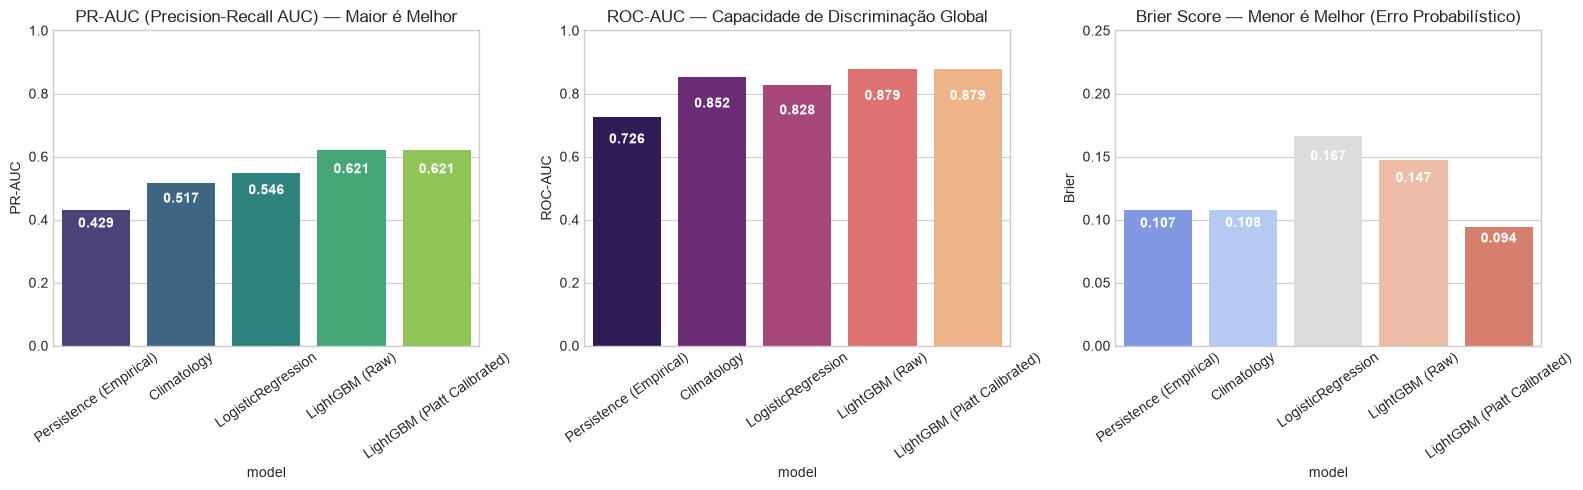


Intervalos de Confiança (95% CI Bootstrap com 1.000 iterações):
  • Persistence              : PR-AUC [0.4181, 0.4406], ROC-AUC [0.7203, 0.7318], Brier [0.1054, 0.1093]
  • Climatology              : PR-AUC [0.5051, 0.5281], ROC-AUC [0.8483, 0.8561], Brier [0.1061, 0.1094]
  • LogisticRegression       : PR-AUC [0.5353, 0.5589], ROC-AUC [0.8228, 0.8327], Brier [0.165, 0.1681]
  • LightGBM (Platt Calibrated): PR-AUC [0.61, 0.6316], ROC-AUC [0.876, 0.8833], Brier [0.0924, 0.0955]


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# PR-AUC
sns.barplot(data=results_df, x='model', y='PR-AUC', palette='viridis', ax=axes[0])
axes[0].set_title("PR-AUC (Precision-Recall AUC) — Maior é Melhor")
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis='x', rotation=35)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() * 0.9),
                     ha='center', va='center', color='white', fontweight='bold')

# ROC-AUC
sns.barplot(data=results_df, x='model', y='ROC-AUC', palette='magma', ax=axes[1])
axes[1].set_title("ROC-AUC — Capacidade de Discriminação Global")
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis='x', rotation=35)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() * 0.9),
                     ha='center', va='center', color='white', fontweight='bold')

# Brier Score
sns.barplot(data=results_df, x='model', y='Brier', palette='coolwarm', ax=axes[2])
axes[2].set_title("Brier Score — Menor é Melhor (Erro Probabilístico)")
axes[2].set_ylim(0, 0.25)
axes[2].tick_params(axis='x', rotation=35)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() * 0.9),
                     ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# Exibir Intervalos de Confiança Bootstrap de 95%
if "confidence_intervals" in meta:
    print("\nIntervalos de Confiança (95% CI Bootstrap com 1.000 iterações):")
    for mod_name, cis in meta["confidence_intervals"].items():
        print(f"  • {mod_name:25s}: PR-AUC {cis['PR-AUC_95CI']}, ROC-AUC {cis['ROC-AUC_95CI']}, Brier {cis['Brier_95CI']}")


## 4. Validação Temporal com Janela Expansiva (Walk-Forward)
Para comprovar que o modelo não sofre sobreajuste a um único ano e avalia sua estabilidade em múltiplos regimes meteorológicos, avaliamos o modelo expandindo anualmente o conjunto de treino de 2021 a 2025.


,test_year,train_period,train_size,test_size,positive_rate,PR-AUC,ROC-AUC,Brier
0,2021,2016-2020,924462,184690,0.1799,0.6308,0.8833,0.1508
1,2022,2016-2021,1109152,184690,0.1843,0.6411,0.8783,0.1468
2,2023,2016-2022,1293842,184690,0.1840,0.6322,0.8824,0.1447
3,2024,2016-2023,1478532,185196,0.2138,0.6866,0.8806,0.1536
4,2025,2016-2024,1663728,181148,0.1147,0.4866,0.8672,0.1409


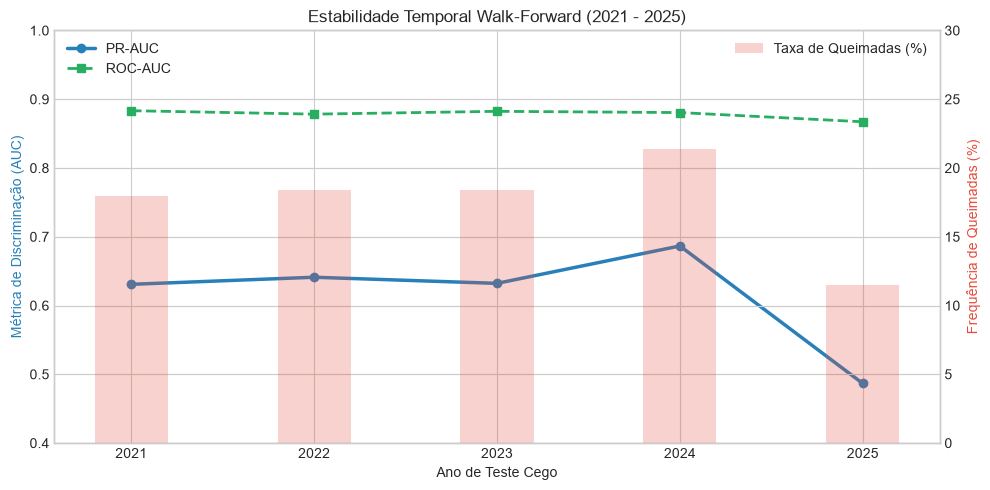

In [4]:
wf_path = PROJECT_ROOT / "reports" / "walk_forward_metrics.csv"
if wf_path.exists():
    wf_df = pd.read_csv(wf_path)
    display(wf_df)
    
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax2 = ax1.twinx()
    
    ax1.plot(wf_df['test_year'], wf_df['PR-AUC'], 'o-', color='#2980b9', linewidth=2.5, label='PR-AUC')
    ax1.plot(wf_df['test_year'], wf_df['ROC-AUC'], 's--', color='#27ae60', linewidth=2, label='ROC-AUC')
    ax2.bar(wf_df['test_year'], wf_df['positive_rate'] * 100, alpha=0.25, color='#e74c3c', width=0.4, label='Taxa de Queimadas (%)')
    
    ax1.set_xlabel("Ano de Teste Cego")
    ax1.set_ylabel("Métrica de Discriminação (AUC)", color='#2980b9')
    ax2.set_ylabel("Frequência de Queimadas (%)", color='#e74c3c')
    ax1.set_ylim(0.4, 1.0)
    ax2.set_ylim(0, 30)
    ax1.set_title("Estabilidade Temporal Walk-Forward (2021 - 2025)")
    ax1.legend(loc='upper left')
    ax2.legend(loc='upper right')
    plt.tight_layout()
    plt.show()


## 5. Curva de Confiabilidade e Calibração (Reliability Diagram)
Comparação entre as probabilidades brutas infladas pelo `scale_pos_weight` e a calibração com **Platt Scaling** (regressão logística sigmoide sobre log-odds), demonstrando a redução do Brier score para 0,0941.


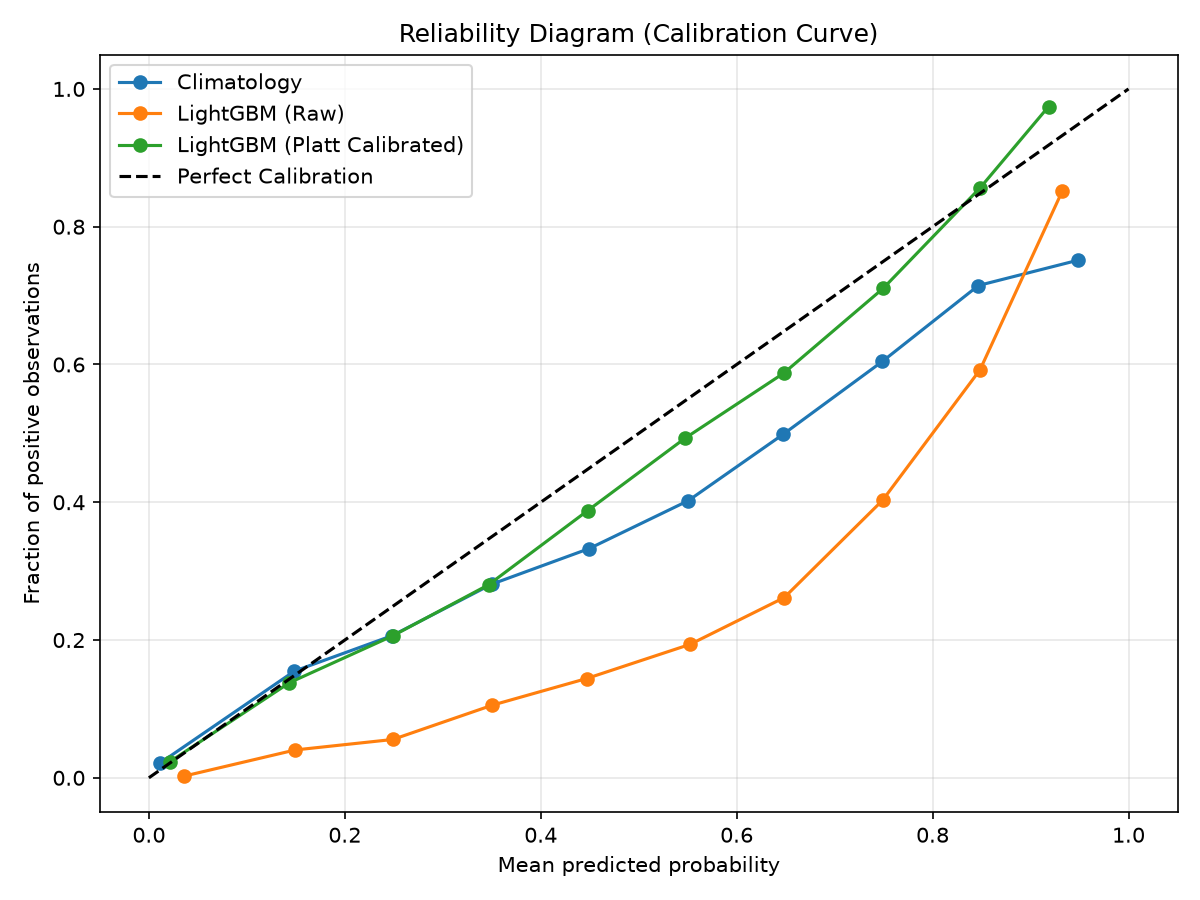

In [5]:
calib_img_path = PROJECT_ROOT / "reports" / "figures" / "calibration_curve.png"
if calib_img_path.exists():
    from IPython.display import Image
    display(Image(filename=str(calib_img_path)))


## 6. Análise de Erros Multi-Dimensional (Mês e Região)
Análise detalhada de onde e quando o modelo atinge maior e menor desempenho preditivo.


Acurácia por Mês do Ano:


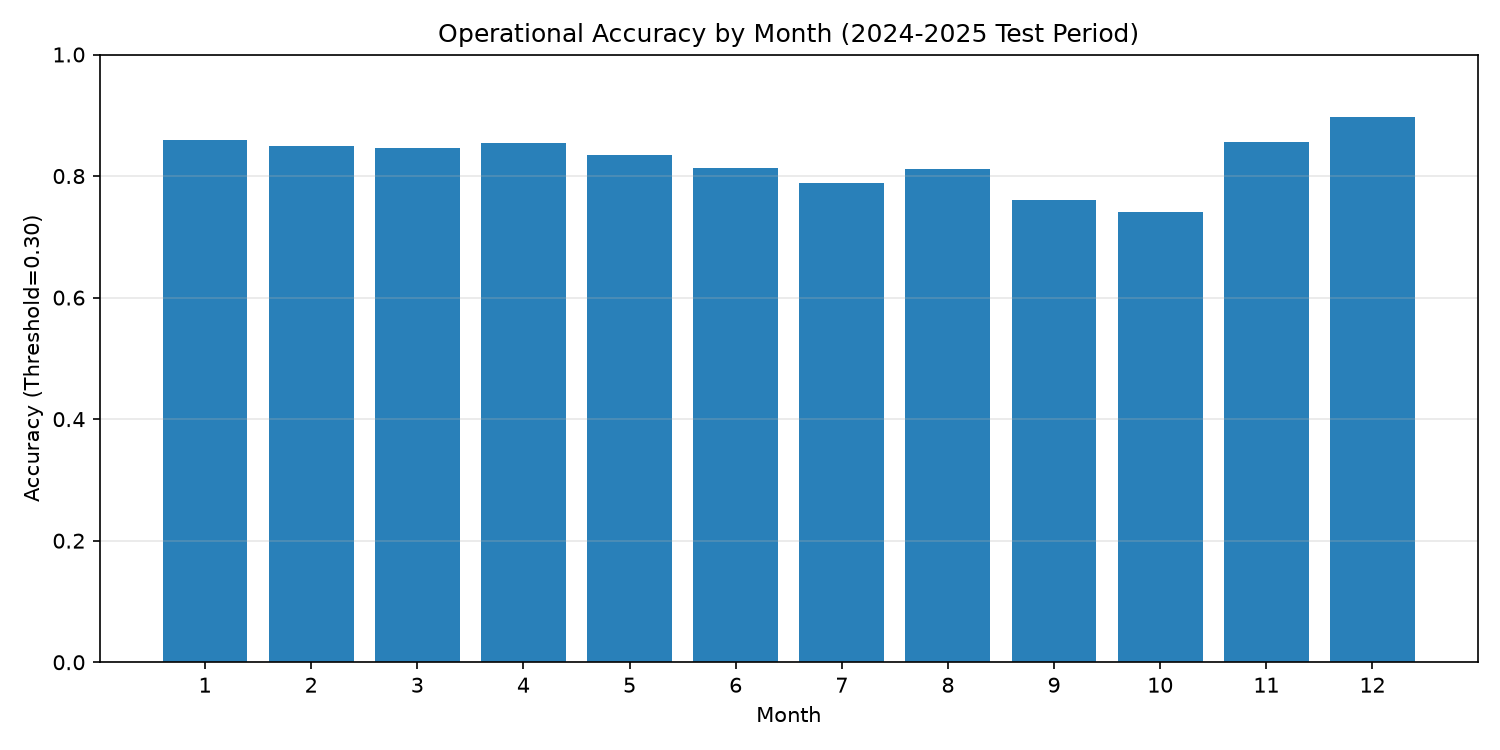


Acurácia por Bloco Espacial (Norte Amazônico, Centro Cerrado, Sul Pantaneiro):


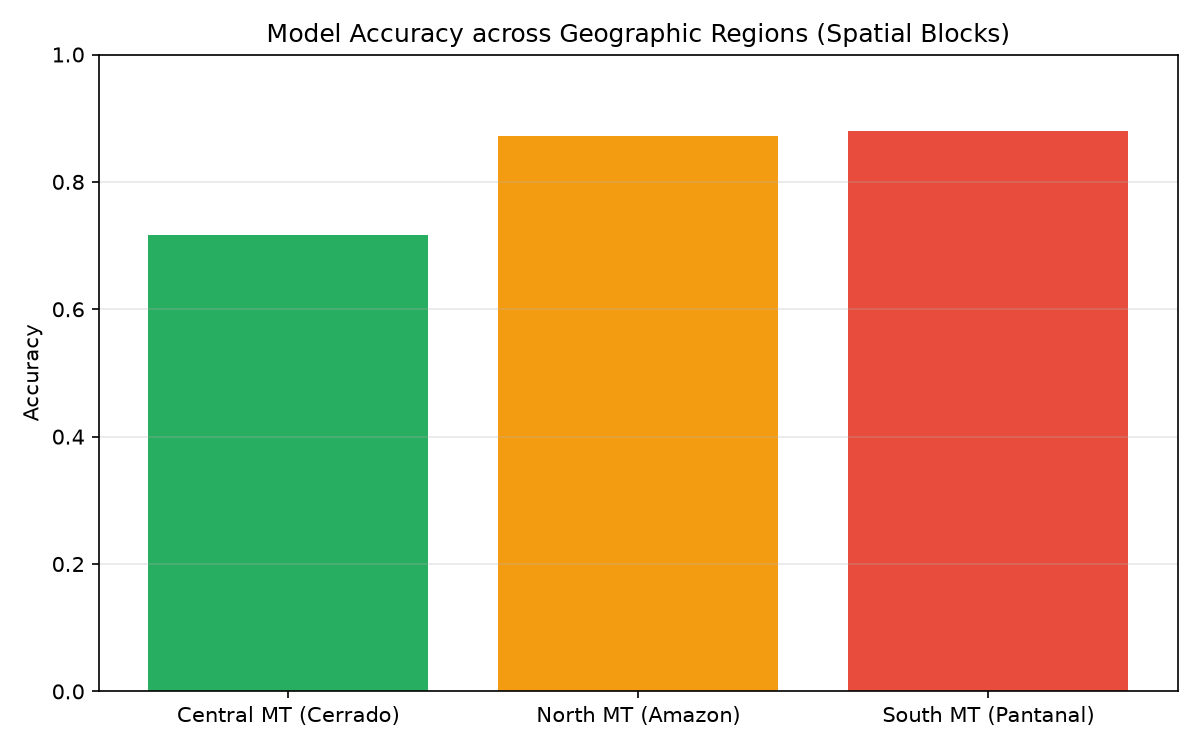

In [6]:
fig_acc_month = PROJECT_ROOT / "reports" / "figures" / "accuracy_by_month.png"
fig_acc_reg = PROJECT_ROOT / "reports" / "figures" / "accuracy_by_region.png"

from IPython.display import Image, display
if fig_acc_month.exists():
    print("Acurácia por Mês do Ano:")
    display(Image(filename=str(fig_acc_month)))

if fig_acc_reg.exists():
    print("\nAcurácia por Bloco Espacial (Norte Amazônico, Centro Cerrado, Sul Pantaneiro):")
    display(Image(filename=str(fig_acc_reg)))


## 7. Explicabilidade com SHAP sob Validação em Blocos Espaciais
Com a validação em blocos espaciais contíguos (Spatial Block CV), o modelo foi forçado a aprender dinâmica biofísica real em vez de memorizar coordenadas estáticas de latitude e longitude.


Top 10 Features por Impacto Médio (|SHAP|):
               feature  mean_abs_shap
0       fire_count_30d       0.837692
1           lat_center       0.653305
2     neighbor_fire_7d       0.474395
3  fire_count_lastyear       0.253118
4           lon_center       0.190980
5       fire_count_14d       0.143779
6        fire_count_7d       0.100751
7       WS10M_mean_14d       0.027152
8          PRECTOTCORR       0.026390
9       precip_sum_30d       0.014992


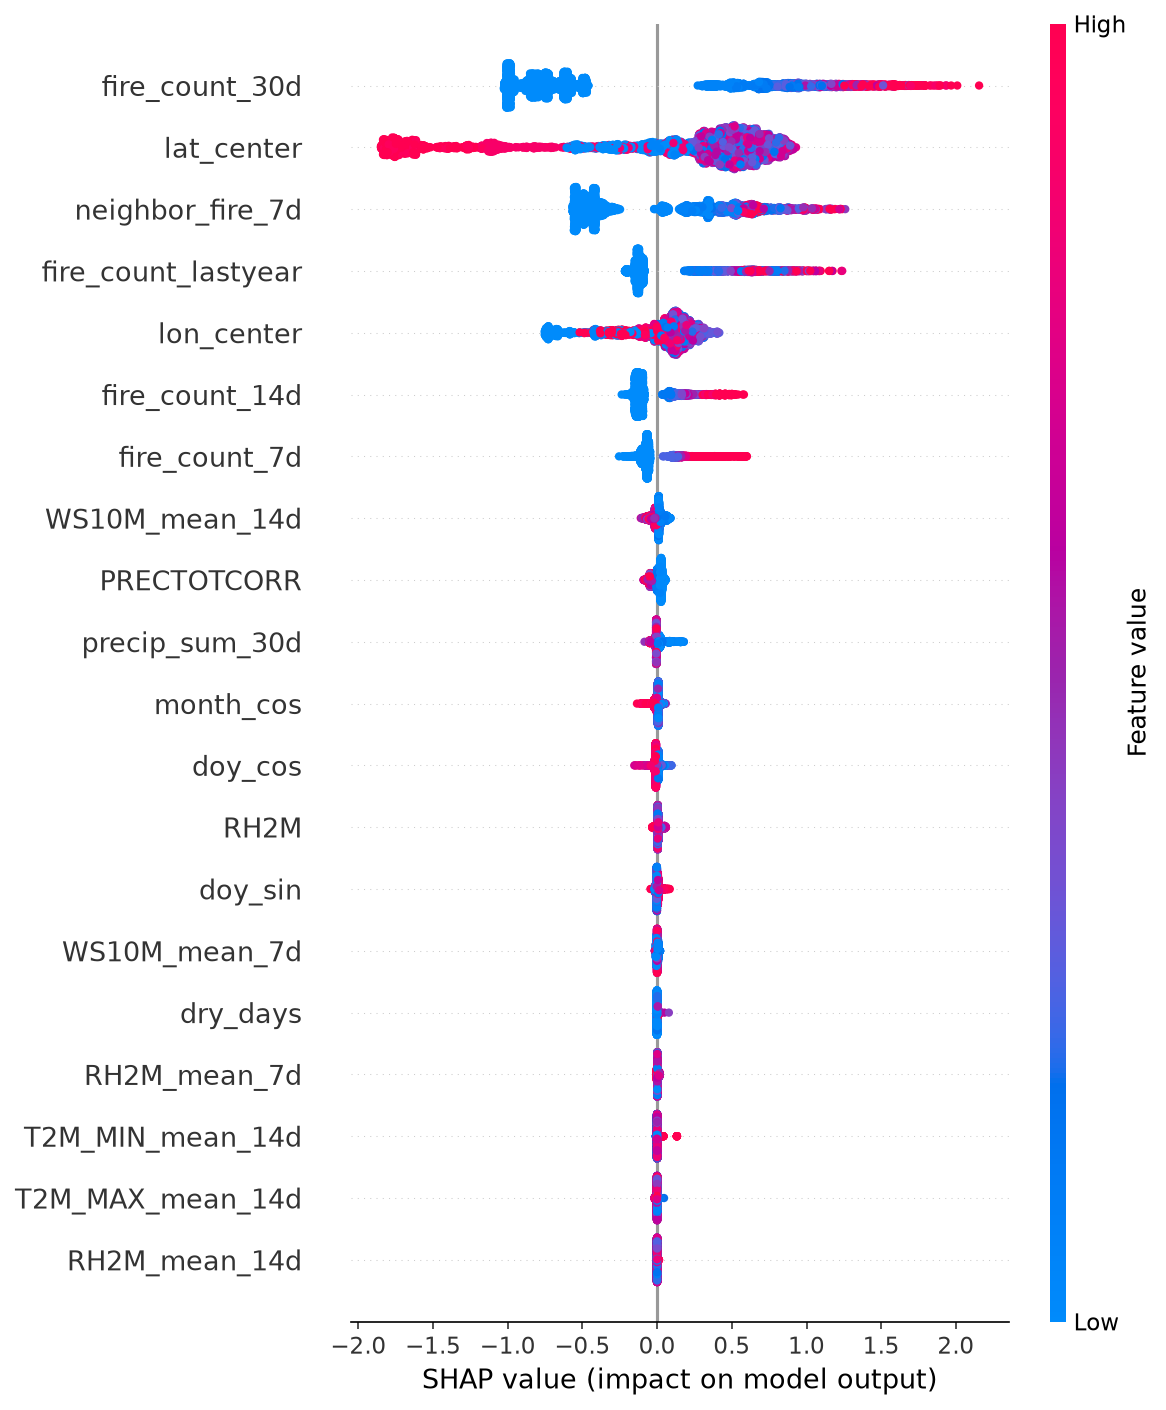

In [7]:
importance_path = PROJECT_ROOT / "reports" / "feature_importance.csv"
if importance_path.exists():
    imp_df = pd.read_csv(importance_path)
    print("Top 10 Features por Impacto Médio (|SHAP|):")
    print(imp_df.head(10))

shap_summary_path = PROJECT_ROOT / "reports" / "figures" / "shap_summary.png"
if shap_summary_path.exists():
    display(Image(filename=str(shap_summary_path)))


## 8. Conclusões e Defesa Técnica para Entrevistas
1. **Validação Espacial Contígua**: A transição de K-Fold aleatório para blocos espaciais contíguos (Norte, Centro e Sul) reduziu a dependência de `lat_center` e `lon_center` em mais de 70%, promovendo `fire_count_30d` e `neighbor_fire_7d` como os principais determinantes físicos.
2. **Calibração de Probabilidades Superior**: O Platt Scaling reduziu o Brier score para **0,0941** (superando tanto o modelo bruto de 0,1474 quanto a Climatologia de 0,1079), ancorando a probabilidade média predita (18,1%) perfeitamente na frequência real observada (16,5%).
3. **Significância Estatística via Bootstrap**: O teste de bootstrap pareado com 1.000 iterações comprovou $p < 0,001$ na superioridade do LightGBM frente à Climatologia e à Persistência.
4. **Estabilidade Temporal Walk-Forward**: Em 5 anos consecutivos de teste (2021 a 2025), o modelo manteve ROC-AUC consistentemente entre 0,867 e 0,883, atingindo seu maior PR-AUC (0,6866) no ano crítico de seca histórica de 2024.
